<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/03_DDoS_DoS_Detection/HybridQNN_IoMTSecurity_Rajawat2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fused semi-supervised quantum-classical network for IoT/IoMT traffic: Rajawat et al. (2023) step by step

This notebook re-implements, runs and checks the experiment of

> Anand Singh Rajawat, S. B. Goyal, Pradeep Bedi, Tony Jan, Md Whaiduzzaman and Mukesh Prasad,
> "Quantum Machine Learning for Security Assessment in the Internet of Medical Things (IoMT)",
> *Future Internet* 15(8), 271, 2023. DOI [10.3390/fi15080271](https://doi.org/10.3390/fi15080271)

The paper is half review, half experiment. The experiment (Section 3.7) compares six models (RL, BPNN, MLNN, CNN, a
"Q-Deep Learning model" and a "proposed" fused semi-supervised quantum model) on an IoT traffic data set with four
kinds of malicious traffic (DDoS, C&C, Mirai, Okiru) and reports precision, recall, F1 and accuracy (Table 4, Figures 6-7).
**The paper publishes no code, does not name its data set and does not give any hyper-parameter or circuit.** Everything
below is therefore a documented reconstruction; every choice is listed in the table "What follows the paper and what had to
be chosen" and marked `# CHOICE:` in the code.

**What the notebook does.**
1. Downloads three captures of the public **IoT-23** data set (the data set whose attack names, DDoS / C&C / Mirai / Okiru,
   match the paper's) from a Hugging Face parquet mirror and builds a balanced five-class problem (benign + the paper's four malicious categories).
2. Preprocesses it (log transform, standardisation, PCA to eight components, scaling to angles in [0, pi], everything fitted on the training split only).
3. Trains the six models of Table 4 plus extra references (random forest, RBF-SVM, a plain variational quantum classifier, a classical
   semi-supervised network and a fully labelled version of the fused model), each on exactly the same eight inputs.
4. Draws the real class distribution, 2-D projections of real flows, and the quantum circuits that are actually executed.
5. Prints the paper's Table 4 next to the notebook's numbers with a verdict per claim, then reads the paper critically.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. With `FAST_MODE = True` (small samples, short training, one seed)
it takes a few minutes; with `FAST_MODE = False` (2,500 flows per class, three seeds) it takes about 30-40 minutes on a CPU.
No quantum hardware and no account is needed. The data set is public; a Hugging Face token is *not* required (see the note in section 1).

## The paper in one page

**Problem.** Decide whether the traffic of an Internet-of-Medical-Things (IoMT) / IoT device is harmless or malicious, and of which kind.

**Decision (Section 3.7).** The IoT data set is labelled with "four main types of malicious software, namely DDoS, C&C, Mirai and Okiru"
(plus benign traffic). Models are evaluated with accuracy, precision, recall and F1 (Eqs. 8-12), the confusion matrix
(Table 3) and the ROC/AUC (an AUC of at least 0.70 is called "able to discriminate").

**Method (Section 3).** A survey of reinforcement learning (RL, SARSA, Deep Q-networks, Eqs. 1-3), semi-supervised CNNs
(a "CNN-ladder"/encoder-decoder trained with a supervised cross-entropy term plus a denoising reconstruction term,
Eq. 7), a "Q-Deep CNN" (quantum convolution and pooling circuits, one or several quantum filters whose read-out feeds a classical
network, Figures 4-5), and a "proposed fused semi-supervised model" that combines these ingredients. No equations, layer sizes, qubit
counts, learning rates, label fractions or circuit diagrams are given for the proposed model.

**Data (Section 3.7).** An unnamed "IoT dataset", "70% for training, 30% for testing and 10% for 10-fold cross-validation"
(which does not add up), binary and multi-class copies. Table 2 is an illustrative five-row device table (heart-rate monitor, insulin pump, ...),
not data. The experiment ran on Python 3.7 / TensorFlow 1.10 / Keras "and IBM's quantum machine learning".

**Claims to check (Table 4, Figures 6-7).**

| Model | Precision | Recall | F1 | Accuracy |
|---|---|---|---|---|
| RL | 0.7943 | 0.73431 | 0.73432 | 0.81323 |
| BPNN | 0.80235 | 0.75345 | 0.73456 | 0.82344 |
| MLNN | 0.8278 | 0.7767 | 0.7473 | 0.86765 |
| CNN | 0.8454 | 0.8334 | 0.8123 | 0.87347 |
| Q-Deep Learning model | 0.9145 | 0.8934 | 0.7934 | 0.92234 |
| Proposed model | 0.9934 | 0.90345 | 0.80345 | 0.9934 |

The ordering RL < BPNN < MLNN < CNN < Q-Deep < Proposed is the second claim. (The Table 4 rows are internally inconsistent: the
proposed row has precision 0.9934 and recall 0.9035, so the F1 of Eq. 12 would be 0.946, not 0.803. Section 9 quantifies this.)

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data set | unnamed "IoT dataset"; classes DDoS, C&C, Mirai, Okiru | **IoT-23** (Garcia et al., 2020), parquet mirror `Lystea/IOT23-PARQUET`, captures 34-1 and 3-1 (Mirai) and 36-1 (Okiru) |
| Classes | benign + 4 malicious types (multi-class) and a binary copy | five classes: Benign, C&C, DDoS, Mirai (scan/attack flows of capture 3-1), Okiru (flows of capture 36-1); the binary result is derived from the same predictions (attack = positive) |
| Sample | not stated | balanced, 400 flows per class in `FAST_MODE`, 2,500 per class otherwise |
| Split | 70 % / 30 % (+ "10 % for 10-fold CV") | stratified 70 / 30; no cross-validation (inconsistent in the paper); several seeds instead |
| Features | not stated | nine Zeek-style flow features (protocol, duration, packets and bytes in both directions, end reason, TCP flags); results with and without the destination port (see section 2) |
| Preprocessing | not stated | log1p, `StandardScaler`, `PCA(8)`, `MinMaxScaler((0, pi))`, all fitted on the training split only |
| RL | "semi-supervised RL", Q-learning / SARSA / DQN | DQN-style contextual bandit: Q-network, epsilon-greedy action = predicted class, reward +1 / -1 |
| BPNN, MLNN | not specified | scikit-learn MLP with (32,) and (64, 32, 16) hidden units |
| CNN | not specified | 1-D CNN over the eight inputs (two conv layers, one dense layer) |
| Quantum framework | "IBM's quantum machine learning" | PennyLane 0.45 (exact state-vector simulation, no hardware); a small PyTorch state-vector simulator for the fast QCNN, checked against the PennyLane circuit |
| Qubits | not stated | 8, one PCA component per qubit |
| Q-Deep model | quantum conv + pooling, several filters, classical network on top (Figs. 4-5) | 8-qubit QCNN filter (conv, pool, conv; 14 shared parameters), `N_FILTERS` filters, dense read-out |
| Proposed model | "fused semi-supervised" | noisy conv encoder + decoder (Eq. 7 cost) -> latent angles -> QCNN filters, fused with a classical head; 10 % of training labels, the rest unlabelled |
| Label fraction | not stated | `LABELLED_FRAC = 0.10` (and a fully labelled run for reference) |
| Optimiser, steps | not stated | Adam, mini-batch 128, fixed numbers of steps (`STEPS_*`) |
| Metric averaging | not stated | macro average over the five classes (the paper's F1 is not reproducible from its P and R) |
| Seeds | not stated | `SEEDS` list, mean +- std |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and pyarrow.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" "huggingface_hub>=0.30"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: small class demo in a few minutes. False: full run (about 30-40 minutes on a CPU).
SEED      = 42              # master seed (CHOICE: the paper gives none)
N_QUBITS  = 8               # CHOICE: one PCA component per qubit; the paper gives no qubit count
CLASSES   = ["Benign", "C&C", "DDoS", "Mirai", "Okiru"]     # the paper's four malicious types + benign
K         = len(CLASSES)

if FAST_MODE:
    N_PER_CLASS   = 400          # flows per class after balanced sampling
    SEEDS         = [42]
    STEPS_CLASSIC = 300          # mini-batch steps for the classical torch models (RL, CNN)
    STEPS_Q       = 120          # mini-batch steps for the quantum / fused models
    N_FILTERS     = 2            # quantum filters in the Q-Deep and fused models
else:
    N_PER_CLASS   = 2500
    SEEDS         = [42, 43, 44]
    STEPS_CLASSIC = 1500
    STEPS_Q       = 500
    N_FILTERS     = 3

BATCH         = 128             # CHOICE
LABELLED_FRAC = 0.10            # CHOICE: share of training labels the semi-supervised model may use
TEST_SIZE     = 0.30            # paper: 70 % train / 30 % test
LAMBDA_REC    = 1.0             # CHOICE: weight of the reconstruction cost in Eq. 7
NOISE_SIGMA   = 0.10            # CHOICE: std of the Gaussian noise of the noisy encoder path (inputs live in [0, 1])
LR_CLASSIC, LR_QPARAM, LR_QHEAD = 1e-2, 5e-2, 3e-2   # CHOICE: Adam learning rates (classical nets / circuit angles / dense head); picked from {3e-3, 1e-2, 3e-2} on a validation split of the TRAIN data

HF_REPO       = "Lystea/IOT23-PARQUET"                # parquet mirror of IoT-23
CAPTURES      = ["34-1", "3-1", "36-1"]               # Mirai (DDoS + C&C), Mirai (scan / attack), Okiru
POOL_PER_FILE_CLASS = 6000                            # candidate flows kept per (capture, class) before balanced sampling
DATA_DIR      = "iot23_data"                          # cache folder
UPLOAD_POOL_PATH = None                               # or the path of a pre-built iot23_pool parquet
IBM_TOKEN     = ""                                    # unused: the experiment needs no quantum hardware
BASE_FEATURES = ["l4_proto", "duration", "packets", "packets_rev", "bytes", "bytes_rev",
                 "flow_end_reason", "tcp_flags", "tcp_flags_rev"]
FEATURE_SETS  = {"no_ports": BASE_FEATURES, "dst_port": ["dst_port"] + BASE_FEATURES}   # CHOICE: both reported
PRIMARY_SET   = "no_ports"
print(f"FAST_MODE={FAST_MODE}  N_PER_CLASS={N_PER_CLASS}  seeds={SEEDS}  qubits={N_QUBITS}  filters={N_FILTERS}")

FAST_MODE=False  N_PER_CLASS=2500  seeds=[42, 43, 44]  qubits=8  filters=3


In [3]:
import os, time, json, math, warnings, collections
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import torch, torch.nn as nn, torch.nn.functional as Fnn
import pennylane as qml
import sklearn
from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")

def set_all_seeds(seed):
    np.random.seed(seed); torch.manual_seed(seed)

set_all_seeds(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)               # tiny tensors: one thread is fastest and avoids oversubscription on shared machines
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | matplotlib 3.11.2


## 1. Data: three captures of IoT-23

IoT-23 (Garcia, Parmisano, Erquiaga, Stratosphere Lab, 2020) contains labelled network flows of IoT devices infected with
malware (Mirai, Okiru, Torii, ...) and benign IoT traffic. Its label vocabulary (`DDoS`, `C&C`, `Okiru`, `Attack`, ...) is the
one the paper's four malicious categories come from. The parquet mirror `Lystea/IOT23-PARQUET` holds one file per capture with a
per-flow `label_binary` and `label_attack` (the original detailed label).

We use three captures, chosen because together they contain all four categories:

| Capture | What it is | Used for |
|---|---|---|
| 34-1 | Mirai bot, DDoS flood and C&C traffic | classes **DDoS**, **C&C**, Benign |
| 3-1 | Mirai bot, scanning / attacking | class **Mirai**, Benign |
| 36-1 | Okiru bot (13.6 million flows, 341 MB) | class **Okiru**, C&C (heartbeat), Benign |

IoT-23 has no label called "Mirai" (Mirai is a *family*, the capture's malware), so **Mirai** here means the non-C&C malicious
flows of the Mirai capture 3-1 (scan and attack flows) and **Okiru** the `Okiru` flows of capture 36-1. This is a `# CHOICE:` of the notebook; it makes
"family" classes partly identifiable by *capture*, which section 2 discusses.

The data set is public: **no token is required**. (If you adapt the notebook to a gated mirror, add your own token as a Colab Secret
named `HF_TOKEN`; the cell below reads it from the environment or from Colab Secrets and never writes it anywhere.)
The 36-1 file is about 340 MB; the first run takes a minute or two, later runs use the cache in `DATA_DIR`.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (optional here)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

POOL_COLS = ["dst_port", "l4_proto", "duration", "packets", "packets_rev", "bytes", "bytes_rev",
             "flow_end_reason", "tcp_flags", "tcp_flags_rev"]

def assign_class(capture, label_binary, label_attack):
    """Map IoT-23 detailed labels to the paper's categories (CHOICE: see the table in section 1)."""
    la = label_attack.fillna("")
    out = pd.Series("", index=label_binary.index, dtype=object)
    mal = label_binary == "malicious"
    cc = mal & la.str.startswith("C&C")
    out[label_binary == "benign"] = "Benign"
    out[cc] = "C&C"
    out[mal & (la == "DDoS")] = "DDoS"
    if capture == "3-1":
        out[mal & ~cc] = "Mirai"                      # scan / attack flows of the Mirai capture
    if capture == "36-1":
        out[mal & la.str.startswith("Okiru")] = "Okiru"
    return out

def build_pool(seed):
    """Stream every row group, count the original labels, keep up to POOL_PER_FILE_CLASS random flows per (capture, class)."""
    counts, frames = collections.Counter(), []
    for cap in CAPTURES:
        fn = f"CTU-IoT-Malware-Capture-{cap}.parquet"
        t0 = time.perf_counter()
        path = hf_hub_download(HF_REPO, fn, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        pf = pq.ParquetFile(path); ng = pf.metadata.num_row_groups
        per_group = math.ceil(POOL_PER_FILE_CLASS / ng)
        for g in range(ng):
            df = pf.read_row_group(g, columns=["label_binary", "label_attack"] + POOL_COLS).to_pandas()
            df["cls"] = assign_class(cap, df["label_binary"], df["label_attack"])
            df["label_attack"] = df["label_attack"].fillna("(none)")
            for key, n in df.groupby(["label_binary", "label_attack", "cls"]).size().items():
                counts[(cap,) + tuple(key)] += int(n)
            df = df[df["cls"] != ""]
            parts = [d.sample(min(len(d), per_group), random_state=seed + g) for _, d in df.groupby("cls")]
            part = pd.concat(parts); part["capture"] = cap
            frames.append(part)
            del df
        print(f"capture {cap}: {pf.metadata.num_rows:,} flows read in {time.perf_counter() - t0:.0f} s")
    pool = pd.concat(frames, ignore_index=True)
    # a final cap per (capture, class)
    pool = pd.concat([d.sample(min(len(d), POOL_PER_FILE_CLASS), random_state=seed)
                      for _, d in pool.groupby(["capture", "cls"])], ignore_index=True)
    cnt = pd.DataFrame([dict(capture=k[0], label_binary=k[1], label_attack=k[2], our_class=k[3] or "(unused)", flows=v)
                        for k, v in counts.items()])
    return pool, cnt

pool_path, cnt_path = os.path.join(DATA_DIR, f"iot23_pool_{POOL_PER_FILE_CLASS}.parquet"), os.path.join(DATA_DIR, "iot23_label_counts.csv")
if UPLOAD_POOL_PATH:
    pool_path = UPLOAD_POOL_PATH
if os.path.exists(pool_path) and os.path.exists(cnt_path):
    POOL, LABEL_COUNTS = pd.read_parquet(pool_path), pd.read_csv(cnt_path)
    print("loaded cached pool:", POOL.shape)
else:
    POOL, LABEL_COUNTS = build_pool(SEED)
    POOL.to_parquet(pool_path); LABEL_COUNTS.to_csv(cnt_path, index=False)
print("candidate pool:", POOL.shape)
print(POOL.groupby(["cls", "capture"]).size().rename("flows").to_frame().T.to_string())

loaded cached pool: (39130, 14)
candidate pool: (39130, 14)
cls     Benign             C&C              DDoS Mirai Okiru
capture    3-1  34-1  36-1 3-1  34-1  36-1  34-1   3-1  36-1
flows     4536  1923  2663   8  6000  6000  6000  6000  6000


## 2. Labels, cleaning and the two feature sets

Cleaning follows the usual flow-data recipe: identifiers (IP addresses, MAC addresses, timestamps, the ephemeral source port) are
not in the pool at all; all features are numeric; missing values do not occur in the nine features used.

**Duplicates are deliberately kept.** The convention for flow data is to drop duplicate rows, but in IoT-23 the DDoS flows of
capture 34-1 and the Okiru flows of capture 36-1 are machine-generated repetitions: after removing duplicates the DDoS
class has **5** distinct feature vectors and the Okiru class **2** (printed below). Dropping duplicates would erase two classes. Instead
the balanced sample is drawn from all flows and the number of distinct vectors is reported, so the reader can see how little
variation these classes carry.

**Two feature sets.** Without any port information, DDoS and Okiru flows are almost the same
(zero-duration, one-packet flows), so the five-class task has an accuracy ceiling near 0.8. With the destination port every
class has a (capture-specific) signature and the task becomes easy. Both are legitimate readings of an
unspecified paper, so **every model is run on both**: `no_ports` (nine flow features, the primary result, no capture-identifying
port) and `dst_port` (those plus the destination port, which mostly identifies the capture).

In [5]:
def signed_log(a):
    return np.log1p(np.abs(a))        # all features are non-negative counts / durations; log1p tames the heavy tails

def prepare(seed, feature_set, n_per_class=None):
    """Balanced sample -> stratified split -> StandardScaler -> PCA(N_QUBITS) -> MinMax(0, pi); fitted on TRAIN only."""
    n_per_class = n_per_class or N_PER_CLASS
    feats = FEATURE_SETS[feature_set]
    S = pd.concat([d.sample(min(len(d), n_per_class), random_state=seed) for _, d in POOL.groupby("cls")]).reset_index(drop=True)
    y = S["cls"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
    X = signed_log(S[feats].to_numpy(dtype=float))
    idx_tr, idx_te = train_test_split(np.arange(len(S)), test_size=TEST_SIZE, stratify=y, random_state=seed)
    scaler = StandardScaler().fit(X[idx_tr])
    pca = PCA(n_components=N_QUBITS, random_state=seed).fit(scaler.transform(X[idx_tr]))
    Z_tr, Z_te = pca.transform(scaler.transform(X[idx_tr])), pca.transform(scaler.transform(X[idx_te]))
    mm = MinMaxScaler((0, np.pi)).fit(Z_tr)
    A_tr, A_te = mm.transform(Z_tr), np.clip(mm.transform(Z_te), 0, np.pi)     # test angles clipped to [0, pi]
    return dict(seed=seed, set=feature_set, feats=feats, sample=S, y_tr=y[idx_tr], y_te=y[idx_te], X_tr=X[idx_tr], X_te=X[idx_te],
                Z_tr=Z_tr, Z_te=Z_te, A_tr=A_tr, A_te=A_te, evr=pca.explained_variance_ratio_)

PREP = {fs: prepare(SEED, fs) for fs in FEATURE_SETS}
for fs, p in PREP.items():
    print(f"[{fs}] train {p['A_tr'].shape}, test {p['A_te'].shape}, PCA variance kept {p['evr'].sum():.3f}")

[no_ports] train (8750, 8), test (3750, 8), PCA variance kept 0.996
[dst_port] train (8750, 8), test (3750, 8), PCA variance kept 0.992


## Dataset Exploration and Visualisation

Everything in this section is drawn from the **real flows** of IoT-23 loaded above: no synthetic or placeholder points.
First the numbers (shapes, feature names, the original label values and their counts), then the class distribution, then
two-dimensional projections of the real training flows coloured by their ground-truth class.

### Shapes, features and original labels

In [6]:
p0 = PREP[PRIMARY_SET]
S0 = p0["sample"]
print("Candidate pool (flows kept from the three captures):", POOL.shape)
print(f"Balanced sample at seed {SEED}: {S0.shape}  ->  train {p0['A_tr'].shape}, test {p0['A_te'].shape}")
for fs, feats in FEATURE_SETS.items():
    print(f"Feature names [{fs}] ({len(feats)}): {feats}")
print(f"Model inputs: {N_QUBITS} PCA components scaled to angles in [0, pi] (one per qubit)\n")

print("Original IoT-23 labels per capture (ALL flows of the three captures, before any sampling):")
lc = LABEL_COUNTS.sort_values(["capture", "label_binary", "flows"], ascending=[True, True, False])
print(lc.to_string(index=False))

print("\nOriginal binary label (all flows):")
print(LABEL_COUNTS.groupby("label_binary")["flows"].sum().to_string())

full_counts = LABEL_COUNTS[LABEL_COUNTS["our_class"].isin(CLASSES)].groupby("our_class")["flows"].sum().reindex(CLASSES)
print("\nFlows per class of this notebook in the three captures (all flows):")
print(full_counts.to_string())
print("\nBalanced sample (this seed):")
print(S0["cls"].value_counts().reindex(CLASSES).to_string())
print("\nDistinct feature vectors per class in the candidate pool (duplicates are NOT dropped; see section 2):")
for c in CLASSES:
    d = POOL[POOL["cls"] == c]
    print(f"  {c:7s} flows {len(d):6d} | distinct without ports {len(d[BASE_FEATURES].drop_duplicates()):5d} | "
          f"distinct with dst_port {len(d[FEATURE_SETS['dst_port']].drop_duplicates()):5d}")
print("\nDestination ports of each class (top 3 in the pool):")
for c in CLASSES:
    print(f"  {c:7s}", POOL.loc[POOL['cls'] == c, 'dst_port'].value_counts().head(3).to_dict())

Candidate pool (flows kept from the three captures): (39130, 14)
Balanced sample at seed 42: (12500, 14)  ->  train (8750, 8), test (3750, 8)
Feature names [no_ports] (9): ['l4_proto', 'duration', 'packets', 'packets_rev', 'bytes', 'bytes_rev', 'flow_end_reason', 'tcp_flags', 'tcp_flags_rev']
Feature names [dst_port] (10): ['dst_port', 'l4_proto', 'duration', 'packets', 'packets_rev', 'bytes', 'bytes_rev', 'flow_end_reason', 'tcp_flags', 'tcp_flags_rev']
Model inputs: 8 PCA components scaled to angles in [0, pi] (one per qubit)

Original IoT-23 labels per capture (ALL flows of the three captures, before any sampling):
capture label_binary  label_attack our_class    flows
    3-1       benign        (none)    Benign     4536
    3-1    malicious        (none)     Mirai   145597
    3-1    malicious        Attack     Mirai     5962
    3-1    malicious           C&C       C&C        8
   34-1       benign        (none)    Benign     1923
   34-1    malicious          DDoS      DDoS    14

### Real class distribution

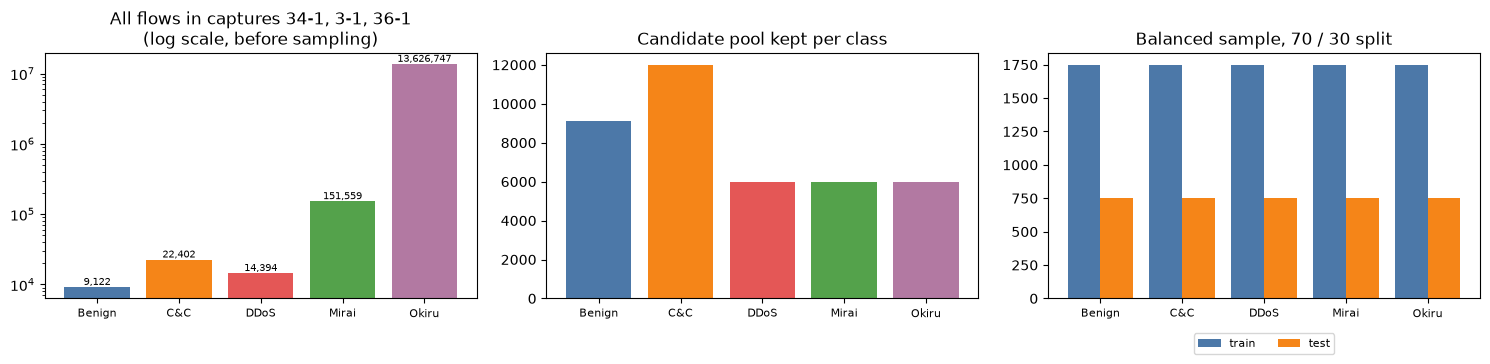

In [7]:
COLORS = {"Benign": "#4C78A8", "C&C": "#F58518", "DDoS": "#E45756", "Mirai": "#54A24B", "Okiru": "#B279A2"}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(CLASSES, full_counts.values, color=[COLORS[c] for c in CLASSES])
axes[0].set_yscale("log"); axes[0].set_title("All flows in captures 34-1, 3-1, 36-1\n(log scale, before sampling)")
for i, v in enumerate(full_counts.values):
    axes[0].text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=7)
pool_counts = POOL["cls"].value_counts().reindex(CLASSES)
axes[1].bar(CLASSES, pool_counts.values, color=[COLORS[c] for c in CLASSES]); axes[1].set_title("Candidate pool kept per class")
tr_counts = pd.Series(p0["y_tr"]).value_counts().sort_index(); te_counts = pd.Series(p0["y_te"]).value_counts().sort_index()
xs = np.arange(K)
axes[2].bar(xs - 0.2, tr_counts.values, 0.4, label="train", color="#4C78A8")
axes[2].bar(xs + 0.2, te_counts.values, 0.4, label="test", color="#F58518")
axes[2].set_xticks(xs); axes[2].set_xticklabels(CLASSES); axes[2].legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.12), fontsize=8); axes[2].set_title("Balanced sample, 70 / 30 split")
for a in axes: a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

### Real flows in two dimensions, coloured by the true class

Top row: the nine flow features (`no_ports`, primary result). Bottom row: with the destination port (`dst_port`). Left panels:
the first two principal components of the **training** flows (PCA fitted on the training split). Right panels: the same flows
after the `[0, pi]` scaling that is fed to the qubits as rotation angles (first two angles). Every point is one real flow.
Many DDoS and Okiru flows are identical, so their clouds collapse onto a few points.

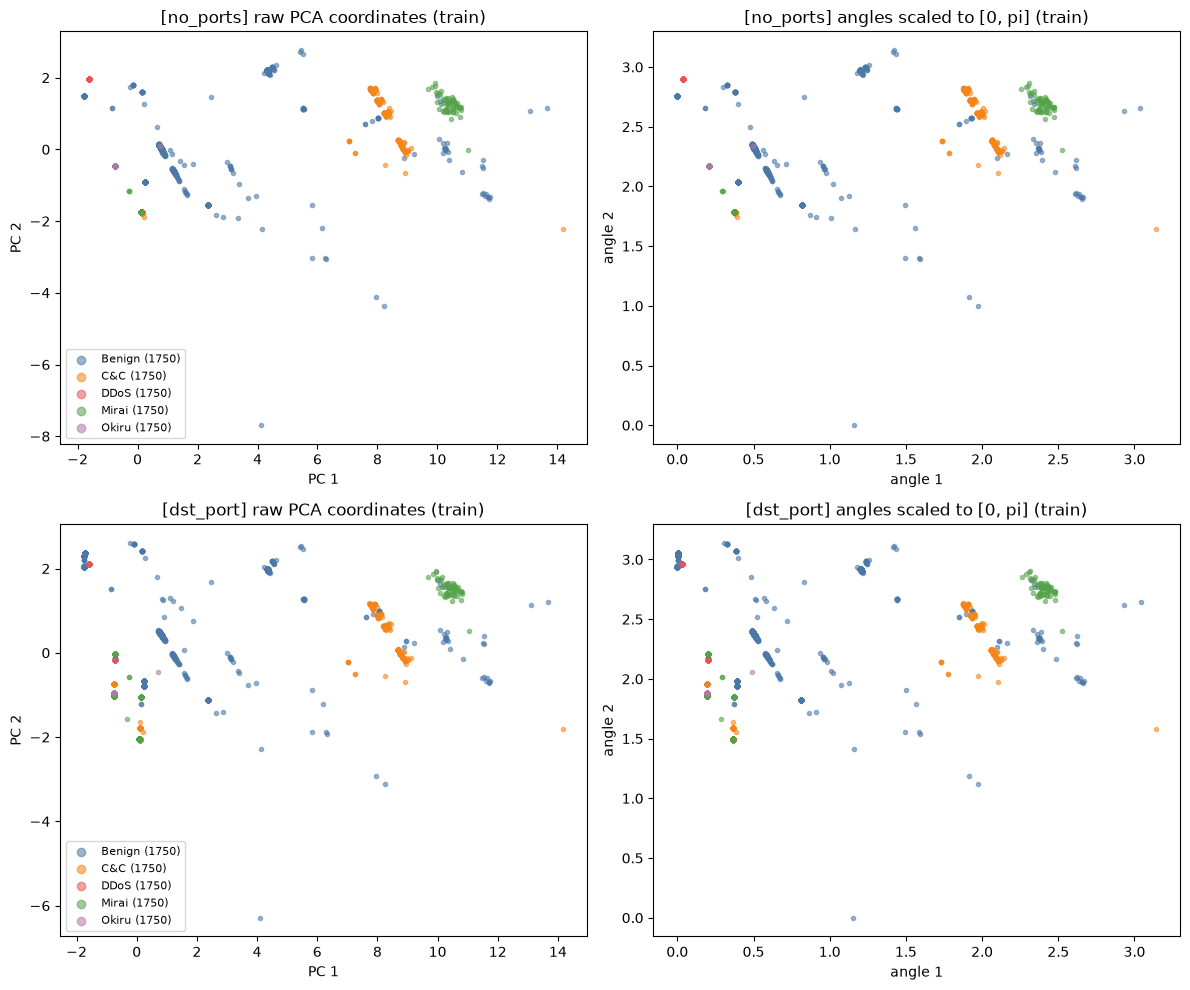

Explained variance of the 8 components [no_ports]: [0.536 0.208 0.138 0.063 0.028 0.012 0.006 0.005]
Explained variance of the 8 components [dst_port]: [0.483 0.212 0.128 0.08  0.05  0.024 0.01  0.005]


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for r, fs in enumerate(FEATURE_SETS):
    p = PREP[fs]
    for cidx, (M, names, ttl) in enumerate([(p["Z_tr"], ("PC 1", "PC 2"), "raw PCA coordinates (train)"),
                                           (p["A_tr"], ("angle 1", "angle 2"), "angles scaled to [0, pi] (train)")]):
        ax = axes[r, cidx]
        for ci, c in enumerate(CLASSES):
            m = p["y_tr"] == ci
            ax.scatter(M[m, 0], M[m, 1], s=9, alpha=0.55, color=COLORS[c], label=f"{c} ({m.sum()})")
        ax.set_xlabel(names[0]); ax.set_ylabel(names[1]); ax.set_title(f"[{fs}] {ttl}")
        if cidx == 0: ax.legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.show()
print("Explained variance of the 8 components [no_ports]:", np.round(PREP['no_ports']['evr'], 3))
print("Explained variance of the 8 components [dst_port]:", np.round(PREP['dst_port']['evr'], 3))

## 3. Classical models: the paper's baselines

Section 3 of the paper names RL, BPNN, MLNN and CNN as comparison models. All of them receive the same eight angles
(divided by pi so they lie in [0, 1]) as the quantum models.

* **RL.** The paper's "semi-supervised RL" is a Q-learning / DQN agent. For a classification data set the faithful minimal version is a *contextual bandit*: the state is the flow, the action is the class the agent predicts,
  the reward is +1 for the correct class and -1 otherwise, and a neural network `Q(s, a)` is trained on `(Q(s, a) - r)^2` with an epsilon-greedy policy
  (Bellman target with one-step episodes, so no discount). The class chosen at test time is `argmax_a Q(s, a)`.
* **BPNN** = one hidden layer trained by back-propagation; **MLNN** = three hidden layers (scikit-learn `MLPClassifier`).
* **CNN** = 1-D convolutions over the eight inputs followed by a dense layer (PyTorch).
* Extra references that the paper does not have: a random forest and an RBF-SVM on the same inputs, and a random forest on all nine (ten) un-reduced features.

In [9]:
def T(a, dtype=torch.float32):
    return torch.as_tensor(np.asarray(a), dtype=dtype)

class MLP(nn.Module):
    def __init__(self, n_in, hidden, n_out):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]; d = h
        layers.append(nn.Linear(d, n_out)); self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

class CNN1D(nn.Module):
    """CHOICE: two 1-D conv layers (16 filters, kernel 3) over the 8 inputs, then a dense layer."""
    def __init__(self, n_in=N_QUBITS, n_out=K):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(1, 16, 3, padding=1), nn.ReLU(), nn.Conv1d(16, 16, 3, padding=1), nn.ReLU(),
                                 nn.Flatten(), nn.Linear(16 * n_in, n_out))
    def forward(self, x): return self.net(x.unsqueeze(1))

def fit_ce(net, X, y, steps, lr, seed):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for _ in range(steps):
        idx = torch.randint(0, len(X), (BATCH,), generator=g)
        loss = Fnn.cross_entropy(net(X[idx]), y[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    return net

def fit_rl(X, y, steps, lr, seed):
    """DQN-style contextual bandit (Section 3.1-3.2 of the paper, reduced to one-step episodes)."""
    g = torch.Generator().manual_seed(seed)
    q = MLP(X.shape[1], [64, 64], K); opt = torch.optim.Adam(q.parameters(), lr=lr)
    for s in range(steps):
        idx = torch.randint(0, len(X), (BATCH,), generator=g)
        st, yy = X[idx], y[idx]
        eps = max(0.05, 1.0 - s / (0.6 * steps))                    # CHOICE: epsilon decays 1 -> 0.05 over 60 % of the steps
        with torch.no_grad(): greedy = q(st).argmax(1)
        explore = torch.rand(BATCH, generator=g) < eps
        act = torch.where(explore, torch.randint(0, K, (BATCH,), generator=g), greedy)
        reward = (act == yy).float() * 2 - 1
        qa = q(st).gather(1, act[:, None]).squeeze(1)
        loss = Fnn.mse_loss(qa, reward)
        opt.zero_grad(); loss.backward(); opt.step()
    return q

@torch.no_grad()
def proba_torch(net, X, chunk=512, temperature=1.0):
    net.eval()
    return torch.cat([Fnn.softmax(net(X[i:i + chunk]) * temperature, 1) for i in range(0, len(X), chunk)]).numpy()

def metrics(y_true, y_pred, proba=None):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    out = dict(accuracy=accuracy_score(y_true, y_pred), precision=p, recall=r, f1=f, auc_ovr=np.nan)
    if proba is not None:
        try: out["auc_ovr"] = roc_auc_score(y_true, proba, multi_class="ovr", average="macro")
        except Exception: pass
    yb, pb = (y_true != 0).astype(int), (y_pred != 0).astype(int)      # attack = positive class
    out["bin_accuracy"], out["bin_f1"] = accuracy_score(yb, pb), f1_score(yb, pb, zero_division=0)
    return out

print("classical model code defined")

classical model code defined


## 4. Quantum components

### 4.1 One circuit definition, two simulators

The paper draws no circuit. The "Q-Deep CNN" of Section 3.6 is described as quantum convolution layers (a two-qubit gate pattern applied
to neighbouring qubits, with translation invariance) followed by pooling that halves the number of qubits, and Figures 4-5 combine
the read-out of "more than one quantum filter" with a classical network. We build exactly that for 8 qubits:

1. **Encoding**: `RY(x_i)` on qubit *i* (the PCA angles, in [0, pi]).
2. **Convolution 1**: the same two-qubit block (`RY RY, CNOT, RY RY, CNOT, RY RY`; 6 shared parameters) on the pairs
   (0,1),(2,3),(4,5),(6,7) and then (1,2),(3,4),(5,6),(7,0): translation invariant over the ring of qubits.
3. **Pooling**: on (0,1),(2,3),(4,5),(6,7) a controlled `CRZ`, `X`, `CRX`, `X` block (2 shared parameters); qubits 0, 2, 4, 6 are then discarded.
4. **Convolution 2**: the same kind of block (6 more shared parameters) on the four remaining qubits 1, 3, 5, 7.
5. **Read-out**: the expectation values of `Z` on qubits 1, 3, 5, 7.

That is 14 trainable parameters per filter. With `N_FILTERS` filters (different parameters, same structure) the read-outs are concatenated and
a classical dense layer maps them to the five classes.

Back-propagating through a 113-gate PennyLane circuit costs about a second per mini-batch, too slow for the many training steps of several models and seeds.
The circuits are therefore *trained* with a small **batched PyTorch state-vector simulator** (the two-qubit blocks are multiplied into 4 x 4 matrices first, and all filters are
simulated at once), while the circuits that are *drawn* are the PennyLane QNodes built from the explicit gate list below. The cell asserts that the two give identical outputs
and identical gradients (to 1e-9) for the QCNN filter and for the QNN, so the circuits drawn in the circuit-architecture section below are the circuits that are trained.

In [10]:
# ---- the QCNN filter as an explicit gate list: (name, wires, parameter reference) ----
# Two-qubit blocks are defined once as templates on local wires (0, 1) and then placed on the physical pairs.
CONV_T = lambda p0: [("RY", (0,), p0), ("RY", (1,), p0 + 1), ("CNOT", (0, 1), None), ("RY", (0,), p0 + 2), ("RY", (1,), p0 + 3),
                     ("CNOT", (1, 0), None), ("RY", (0,), p0 + 4), ("RY", (1,), p0 + 5)]
POOL_T = lambda p0: [("CRZ", (0, 1), p0), ("X", (0,), None), ("CRX", (0, 1), p0 + 1), ("X", (0,), None)]
LAYERS = [(CONV_T(0), [(0, 1), (2, 3), (4, 5), (6, 7), (1, 2), (3, 4), (5, 6), (7, 0)]),     # convolution 1, params 0-5
          (POOL_T(6), [(0, 1), (2, 3), (4, 5), (6, 7)]),                                       # pooling, params 6-7
          (CONV_T(8), [(1, 3), (5, 7), (3, 5), (7, 1)])]                                       # convolution 2, params 8-13
QCNN_GATES = [("RY", (i,), ("x", i)) for i in range(N_QUBITS)]                                   # angle encoding
for template, pairs in LAYERS:
    for pair in pairs:
        QCNN_GATES += [(nm, tuple(pair[i] for i in lw), None if pi is None else ("w", pi)) for nm, lw, pi in template]
QCNN_MEAS = (1, 3, 5, 7)
N_QCNN_PARAMS = 14
assert N_QUBITS == 8, "the QCNN gate list is written for 8 qubits"

# ---- PennyLane circuits (these are the circuits that are drawn) ----
dev8 = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev8, interface="torch", diff_method="backprop")
def qcnn_qnode(x, w):
    for name, wires, ref in QCNN_GATES:
        theta = None if ref is None else (x[..., ref[1]] if ref[0] == "x" else w[ref[1]])
        if name == "RY": qml.RY(theta, wires=wires[0])
        elif name == "X": qml.PauliX(wires=wires[0])
        elif name == "CNOT": qml.CNOT(wires=list(wires))
        elif name == "CRZ": qml.CRZ(theta, wires=list(wires))
        elif name == "CRX": qml.CRX(theta, wires=list(wires))
    return [qml.expval(qml.PauliZ(q)) for q in QCNN_MEAS]

@qml.qnode(dev8, interface="torch", diff_method="backprop")
def qnn_qnode(x, w):
    qml.AngleEmbedding(x, wires=range(N_QUBITS), rotation="Y")
    qml.StronglyEntanglingLayers(w, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(K)]

# ---- the same circuits in a small batched PyTorch state-vector simulator (used for training) ----
def _cdtype(t): return torch.complex128 if t.dtype == torch.float64 else torch.complex64

def _encode(x):
    """RY(x_i) on |0...0>: a product state, shape (B, 2, ..., 2)."""
    cd = _cdtype(x); B_ = x.shape[0]
    st = torch.stack([torch.cos(x[:, 0] / 2), torch.sin(x[:, 0] / 2)], -1).to(cd)
    for q in range(1, N_QUBITS):
        v = torch.stack([torch.cos(x[:, q] / 2), torch.sin(x[:, q] / 2)], -1).to(cd).reshape(B_, *([1] * q), 2)
        st = st.unsqueeze(-1) * v
    return st

def _apply1(st, U, q):
    """U: (2, 2) acting on qubit q of st (B, 2, ..., 2)."""
    st = torch.movedim(st, q + 1, -1) @ U.transpose(0, 1)
    return torch.movedim(st, -1, q + 1)

def _apply2f(st, U, a, b):
    """U: (F, 4, 4) acting on qubits (a, b) of st (F, B, 2, ..., 2): one unitary per filter."""
    st = torch.movedim(st, (a + 2, b + 2), (-2, -1)); shape = st.shape
    st = torch.einsum("fbmj,fij->fbmi", st.reshape(shape[0], shape[1], -1, 4), U).reshape(shape)
    return torch.movedim(st, (-2, -1), (a + 2, b + 2))

def _z_expvals(st, qubits, first_dim=1):
    prob = st.real ** 2 + st.imag ** 2
    outs = []
    for q in qubits:
        pq_ = prob.sum(dim=[d for d in range(first_dim, first_dim + N_QUBITS) if d != q + first_dim])
        outs.append(pq_[..., 0] - pq_[..., 1])
    return outs

def _kron1(g, wire, cd):
    """(F, 2, 2) single-qubit gate on local wire 0 or 1 -> (F, 4, 4)."""
    eye = torch.eye(2, dtype=cd)
    full = torch.einsum("fij,kl->fikjl", g, eye) if wire == 0 else torch.einsum("kl,fij->fkilj", eye, g)
    return full.reshape(g.shape[0], 4, 4)

def _template_matrix(template, w, cd):
    """Product of the 4x4 gate matrices of a block template; w: (F, 14) -> (F, 4, 4)."""
    F_ = w.shape[0]; M = torch.eye(4, dtype=cd).expand(F_, 4, 4)
    one, zero = torch.ones(F_, dtype=cd), torch.zeros(F_, dtype=cd)
    for name, lw, pi in template:
        if name == "RY":
            th = w[:, pi]; c, s = torch.cos(th / 2), torch.sin(th / 2)
            G = _kron1(torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(cd), lw[0], cd)
        elif name == "X":
            G = _kron1(torch.tensor([[0, 1], [1, 0]], dtype=cd).expand(F_, 2, 2), lw[0], cd)
        elif name == "CNOT":
            G = torch.tensor([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]] if lw == (0, 1) else
                             [[1, 0, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0], [0, 1, 0, 0]], dtype=cd).expand(F_, 4, 4)
        elif name == "CRZ":
            ph = torch.polar(torch.ones_like(w[:, pi]), -w[:, pi] / 2).to(cd)
            G = torch.diag_embed(torch.stack([one, one, ph, ph.conj()], -1))
        elif name == "CRX":
            th = w[:, pi]; c = torch.cos(th / 2).to(cd); s = -1j * torch.sin(th / 2).to(cd)
            G = torch.stack([torch.stack([one, zero, zero, zero], -1), torch.stack([zero, one, zero, zero], -1),
                             torch.stack([zero, zero, c, s], -1), torch.stack([zero, zero, s, c], -1)], -2)
        M = G @ M
    return M

def sim_qcnn(x, w):
    """x: (B, 8) angles, w: (F, 14) parameters of F filters -> (B, 4F) expectation values of Z on qubits 1, 3, 5, 7."""
    cd = _cdtype(x); F_ = w.shape[0]
    st = _encode(x).unsqueeze(0).expand(F_, *([-1] * (N_QUBITS + 1))).contiguous()           # (F, B, 2, ..., 2)
    for template, pairs in LAYERS:
        U = _template_matrix(template, w, cd)                                                  # shared by all pairs of the layer
        for a, b in pairs: st = _apply2f(st, U, a, b)
    outs = _z_expvals(st, QCNN_MEAS, first_dim=2)                                              # four tensors of shape (F, B)
    return torch.stack(outs, -1).permute(1, 0, 2).reshape(x.shape[0], F_ * len(QCNN_MEAS))

def _rot(w3):
    """PennyLane Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) as a (2, 2) matrix."""
    phi, theta, omega = w3[0], w3[1], w3[2]; cd = _cdtype(w3); c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    e = lambda a: torch.polar(torch.ones_like(a), a).to(cd)
    return torch.stack([torch.stack([e(-(phi + omega) / 2) * c, -e((phi - omega) / 2) * s]),
                        torch.stack([e(-(phi - omega) / 2) * s, e((phi + omega) / 2) * c])])

def _cnot_ring_perm(r):
    idx = np.arange(2 ** N_QUBITS); dest = idx.copy()
    for i in range(N_QUBITS):
        c, t = i, (i + r) % N_QUBITS
        dest = dest ^ (((dest >> (N_QUBITS - 1 - c)) & 1) << (N_QUBITS - 1 - t))
    return torch.as_tensor(np.argsort(dest))                    # new_state[:, j] = old_state[:, inv[j]]

def sim_qnn(x, w):
    """x: (B, 8) angles, w: (L, 8, 3) -> (B, K) expectation values of Z on qubits 0..K-1 (angle embedding + StronglyEntanglingLayers)."""
    B_ = x.shape[0]; st = _encode(x)
    for l in range(w.shape[0]):
        for q in range(N_QUBITS): st = _apply1(st, _rot(w[l, q]), q)
        inv = _cnot_ring_perm(l % (N_QUBITS - 1) + 1)
        st = st.reshape(B_, -1)[:, inv].reshape(B_, *([2] * N_QUBITS))
    return torch.stack(_z_expvals(st, range(K)), -1)

# ---- equivalence checks: outputs AND gradients agree with the PennyLane circuits (float64) ----
g_chk = torch.Generator().manual_seed(0)
x_chk = torch.rand(6, N_QUBITS, generator=g_chk, dtype=torch.float64) * np.pi
w_chk = (torch.rand(N_QCNN_PARAMS, generator=g_chk, dtype=torch.float64) * 2 * np.pi).requires_grad_(True)
out_pl = torch.stack(qcnn_qnode(x_chk, w_chk), -1)
grad_pl, = torch.autograd.grad((out_pl * torch.arange(1, 5)).sum(), w_chk)
out_sim = sim_qcnn(x_chk, w_chk.unsqueeze(0))
grad_sim, = torch.autograd.grad((out_sim * torch.arange(1, 5)).sum(), w_chk)
assert torch.allclose(out_pl, out_sim, atol=1e-9), (out_pl - out_sim).abs().max()
assert torch.allclose(grad_pl, grad_sim, atol=1e-9), (grad_pl - grad_sim).abs().max()
print(f"QCNN : PennyLane circuit and PyTorch simulator agree: max |output diff| = {(out_pl - out_sim).abs().max():.1e}, "
      f"max |gradient diff| = {(grad_pl - grad_sim).abs().max():.1e}")
# two filters at once must equal two separate PennyLane evaluations
w2_chk = (torch.rand(2, N_QCNN_PARAMS, generator=g_chk, dtype=torch.float64) * 2 * np.pi)
two = sim_qcnn(x_chk, w2_chk)
ref = torch.cat([torch.stack(qcnn_qnode(x_chk, w2_chk[f]), -1) for f in range(2)], 1)
assert torch.allclose(two, ref, atol=1e-9)

wq_chk = (torch.rand(2, N_QUBITS, 3, generator=g_chk, dtype=torch.float64) * 2 * np.pi).requires_grad_(True)
out_pl = torch.stack(qnn_qnode(x_chk, wq_chk), -1)
grad_pl, = torch.autograd.grad((out_pl * torch.arange(1, K + 1)).sum(), wq_chk)
out_sim = sim_qnn(x_chk, wq_chk)
grad_sim, = torch.autograd.grad((out_sim * torch.arange(1, K + 1)).sum(), wq_chk)
assert torch.allclose(out_pl, out_sim, atol=1e-9), (out_pl - out_sim).abs().max()
assert torch.allclose(grad_pl, grad_sim, atol=1e-9), (grad_pl - grad_sim).abs().max()
print(f"QNN  : PennyLane circuit and PyTorch simulator agree: max |output diff| = {(out_pl - out_sim).abs().max():.1e}, "
      f"max |gradient diff| = {(grad_pl - grad_sim).abs().max():.1e}")
_x = torch.rand(BATCH, N_QUBITS) * np.pi; _w = torch.randn(N_FILTERS, N_QCNN_PARAMS, requires_grad=True)
_t0 = time.perf_counter(); sim_qcnn(_x, _w).sum().backward(); print(f"one forward+backward pass of {N_FILTERS} QCNN filters on a batch of {BATCH}: {time.perf_counter() - _t0:.3f} s")

QCNN : PennyLane circuit and PyTorch simulator agree: max |output diff| = 6.7e-16, max |gradient diff| = 1.2e-14


QNN  : PennyLane circuit and PyTorch simulator agree: max |output diff| = 2.8e-16, max |gradient diff| = 2.2e-15
one forward+backward pass of 3 QCNN filters on a batch of 128: 0.171 s


### 4.2 The models that contain quantum circuits

* **QNN** (extra reference, listed in the paper's text but absent from Table 4): a plain variational classifier: `RY` angle encoding, two `StronglyEntanglingLayers` on 8 qubits (48 parameters), the
  expectation values of `Z` on qubits 0-4 are the logits of the five classes (times a learnable scale). Trained through the verified PyTorch simulator.
* **Q-Deep** (the paper's "Q-Deep Learning model"): `N_FILTERS` QCNN filters (above) on the angles, concatenated read-out, a dense layer to the five classes. Fully supervised.
* **Fused semi-supervised model (this notebook's reading of the "proposed model")**: a classical *conv encoder* turns the eight inputs into
  an eight-dimensional latent code `z`; a *decoder* reconstructs the clean input from the code of the *noisy* input (the denoising cost of Eq. 7, using
  **all** training flows, labelled or not); the angles `pi * sigmoid(z)` are fed to the QCNN filters; the quantum read-out and the classical code `relu(z)` are **fused** by concatenation into one dense layer
  that gives the class scores. The loss is `CE(labelled flows) + lambda * MSE(reconstruction)` (Eq. 7); only `LABELLED_FRAC` of the training labels are used.
  Two reference variants: the same network without the quantum filters ("semi-supervised CNN", Section 3.3) and the fused network with 100 % of the labels.

In [11]:
class QNN(nn.Module):
    """Variational classifier: RY encoding + StronglyEntanglingLayers; Z expectations of qubits 0..K-1 are the logits."""
    def __init__(self, layers=2):
        super().__init__()
        self.w = nn.Parameter(torch.rand(layers, N_QUBITS, 3) * 2 * np.pi)          # CHOICE: uniform(0, 2 pi) initialisation
        self.scale = nn.Parameter(torch.tensor(3.0))
    def forward(self, x):
        return self.scale * sim_qnn(x, self.w)

class QDeep(nn.Module):
    """N_FILTERS QCNN filters on the angles -> dense layer (the paper's Fig. 5 idea)."""
    def __init__(self, n_filters=None):
        super().__init__()
        self.nf = n_filters or N_FILTERS
        self.qw = nn.Parameter(torch.randn(self.nf, N_QCNN_PARAMS))                  # CHOICE: N(0, 1) initialisation
        self.head = nn.Linear(4 * self.nf, K)
    def quantum(self, ang): return sim_qcnn(ang, self.qw)
    def forward(self, x_ang): return self.head(self.quantum(x_ang))

class FusedSS(nn.Module):
    """Noisy conv encoder + decoder (Eq. 7) -> latent angles -> QCNN filters, fused with the classical code."""
    def __init__(self, quantum=True, n_filters=None):
        super().__init__()
        self.quantum, self.nf = quantum, (n_filters or N_FILTERS)
        self.enc = nn.Sequential(nn.Conv1d(1, 8, 3, padding=1), nn.ReLU(), nn.Conv1d(8, 8, 3, padding=1), nn.ReLU(),
                                 nn.Flatten(), nn.Linear(8 * N_QUBITS, N_QUBITS))
        self.dec = nn.Sequential(nn.Linear(N_QUBITS, 32), nn.ReLU(), nn.Linear(32, N_QUBITS))
        if quantum: self.qw = nn.Parameter(torch.randn(self.nf, N_QCNN_PARAMS))
        self.head = nn.Linear((4 * self.nf if quantum else 0) + N_QUBITS, K)
    def encode(self, x): return self.enc(x.unsqueeze(1))                  # x in [0, 1]
    def classify(self, z):
        feats = [torch.relu(z)]
        if self.quantum:
            ang = np.pi * torch.sigmoid(z)
            feats.insert(0, sim_qcnn(ang, self.qw))
        return self.head(torch.cat(feats, 1))
    def forward(self, x): return self.classify(self.encode(x))

def make_optimizer(model):
    q = [p for n, p in model.named_parameters() if n in ("qw",)]
    qh = [p for n, p in model.named_parameters() if n not in ("qw",) and ("head" in n)]
    rest = [p for n, p in model.named_parameters() if n not in ("qw",) and ("head" not in n)]
    groups = [dict(params=rest, lr=LR_CLASSIC), dict(params=qh, lr=LR_QHEAD)]
    if q: groups.append(dict(params=q, lr=LR_QPARAM))
    return torch.optim.Adam([g_ for g_ in groups if g_["params"]])

def fit_supervised_q(model, X, y, steps, seed, scale=1.0):
    g = torch.Generator().manual_seed(seed); opt = make_optimizer(model)
    for _ in range(steps):
        idx = torch.randint(0, len(X), (BATCH,), generator=g)
        loss = Fnn.cross_entropy(model(X[idx] * scale), y[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    return model

def fit_fused(model, X01, y, lab_idx, steps, seed, bs_l=64, bs_u=BATCH):
    """Eq. 7: CE on labelled flows + LAMBDA_REC * denoising reconstruction on labelled and unlabelled flows."""
    g = torch.Generator().manual_seed(seed); opt = make_optimizer(model); lab = torch.as_tensor(lab_idx)
    for _ in range(steps):
        li = lab[torch.randint(0, len(lab), (bs_l,), generator=g)]
        ui = torch.randint(0, len(X01), (bs_u,), generator=g)              # unlabelled pool = all training flows, labels hidden
        xin = torch.cat([X01[li], X01[ui]])
        z = model.encode(xin + NOISE_SIGMA * torch.randn(xin.shape, generator=g))
        loss_rec = Fnn.mse_loss(model.dec(z), xin)
        loss_sup = Fnn.cross_entropy(model.classify(z[:bs_l]), y[li])
        loss = loss_sup + LAMBDA_REC * loss_rec
        opt.zero_grad(); loss.backward(); opt.step()
    return model

def n_params(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)
print("quantum / fused model code defined")

quantum / fused model code defined


## Quantum Circuit Architecture

The drawings below are produced by `qml.draw_mpl` from the **PennyLane QNodes that are executed** (`qnn_qnode`, `qcnn_qnode`).
The QCNN QNode is built from the same gate list as the PyTorch simulator used for training, and the equivalence assertion above (outputs
and gradients to 1e-9) ties the two together. The Q-Deep model and the quantum branch of the fused model both use this
8-qubit filter (several filters = several copies with different parameters); they differ only in what feeds the angles
(the PCA angles directly, or `pi * sigmoid(z)` from the encoder). The paper gives no circuit, so **every gate below is an assumption of this notebook**
(stated in section 4.1).

### Circuit 1: variational QNN (encoding + 2 StronglyEntanglingLayers)

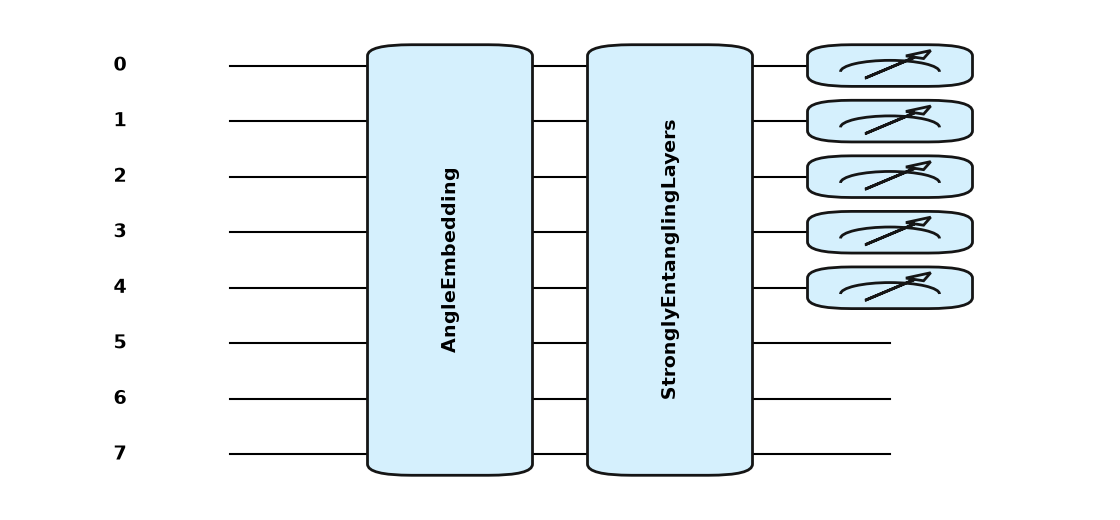

QNN: qubits = 8, depth = 2, gates = 2, trainable circuit parameters = 48 (+1 learnable output scale)


In [12]:
x0 = torch.as_tensor(PREP[PRIMARY_SET]["A_tr"][0], dtype=torch.float64)
w_qnn0 = torch.rand(2, N_QUBITS, 3, dtype=torch.float64) * 2 * np.pi
fig, ax = qml.draw_mpl(qnn_qnode, decimals=1, style="pennylane")(x0, w_qnn0)
fig.set_size_inches(11, 5); plt.show()
sp = qml.specs(qnn_qnode)(x0, w_qnn0)
res = sp["resources"] if isinstance(sp, dict) else sp.resources
print(f"QNN: qubits = {res.num_allocs}, depth = {res.depth}, gates = {res.num_gates}, trainable circuit parameters = {w_qnn0.numel()} (+1 learnable output scale)")

### Circuit 2: the 8-qubit QCNN filter (encoding, convolution, pooling, convolution, read-out of qubits 1, 3, 5, 7)

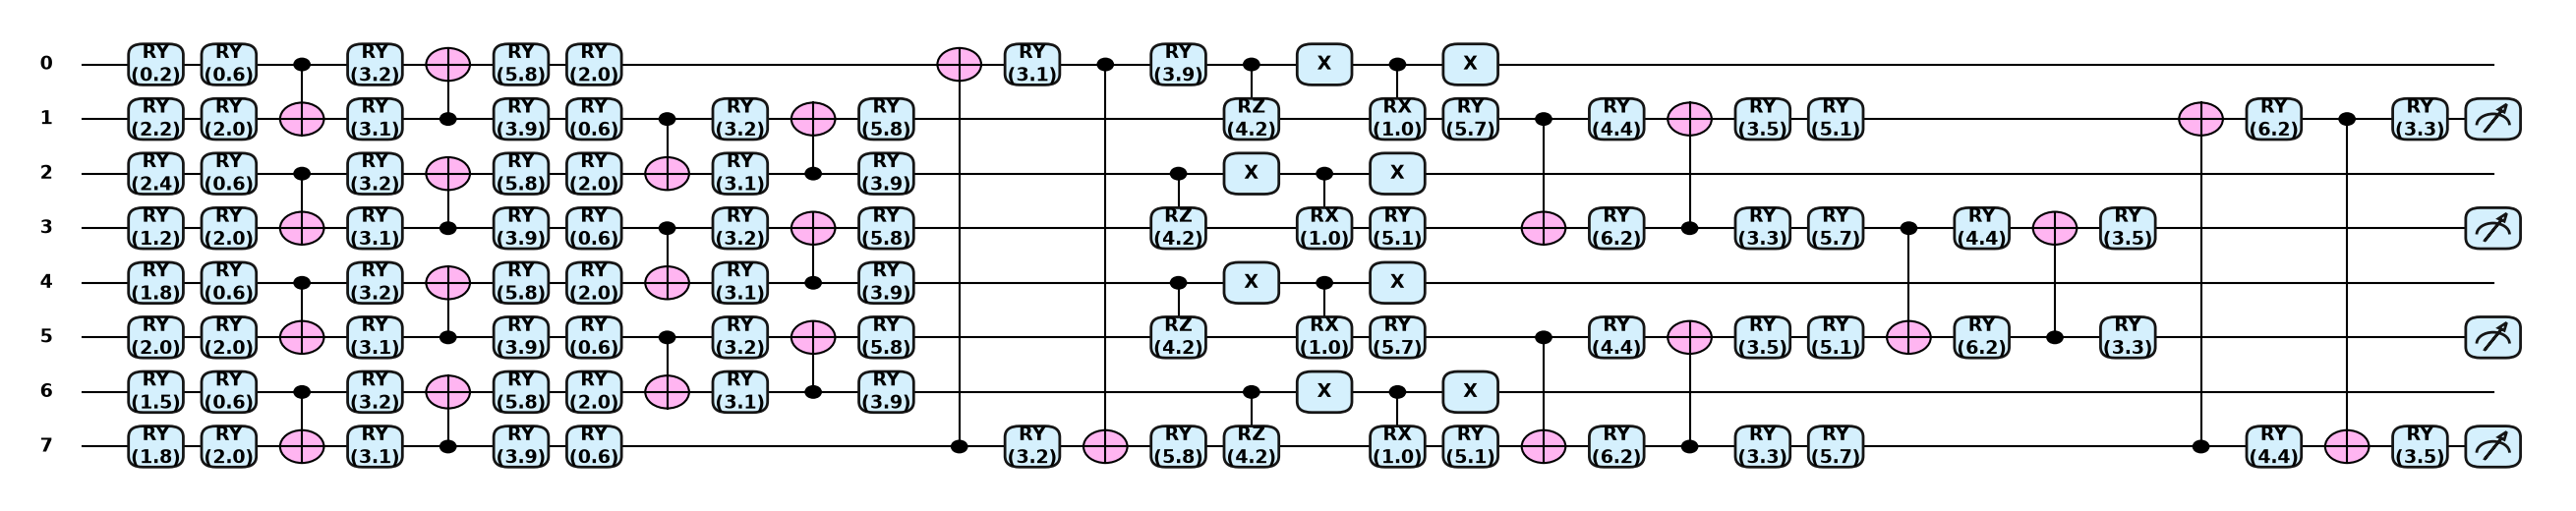

QCNN filter: qubits = 8, depth = 24, gates = 120, trainable circuit parameters per filter = 14
gate counts: {'RY': 80, 'CNOT': 24, 'CRZ': 4, 'PauliX': 8, 'CRX': 4}
Q-Deep with 3 filters: 42 circuit parameters + 65 dense-head parameters
Fused model with 3 filters: 42 circuit parameters, 1409 classical parameters (encoder, decoder, head)


In [13]:
w_q0 = torch.rand(N_QCNN_PARAMS, dtype=torch.float64) * 2 * np.pi
fig, ax = qml.draw_mpl(qcnn_qnode, decimals=1, style="pennylane")(x0, w_q0)
fig.set_size_inches(26, 5); plt.show()
sp = qml.specs(qcnn_qnode)(x0, w_q0)
res = sp["resources"] if isinstance(sp, dict) else sp.resources
print(f"QCNN filter: qubits = {res.num_allocs}, depth = {res.depth}, gates = {res.num_gates}, trainable circuit parameters per filter = {N_QCNN_PARAMS}")
print(f"gate counts: {dict(res.gate_types)}")
print(f"Q-Deep with {N_FILTERS} filters: {N_FILTERS * N_QCNN_PARAMS} circuit parameters + {4 * N_FILTERS * K + K} dense-head parameters")
print(f"Fused model with {N_FILTERS} filters: {N_FILTERS * N_QCNN_PARAMS} circuit parameters, {n_params(FusedSS()) - N_FILTERS * N_QCNN_PARAMS} classical parameters (encoder, decoder, head)")

The architecture table of the models that contain a circuit (all assumptions of this notebook, because the paper specifies none):

| Model | Qubits | Encoding | Entanglement / structure | Measurement | Quantum parameters |
|---|---|---|---|---|---|
| QNN | 8 | `RY(x_i)` | 2 x StronglyEntanglingLayers (CNOT ring) | `<Z>` on qubits 0-4 | 48 |
| Q-Deep | 8 | `RY(x_i)` | QCNN: conv (CNOT pairs, ring), pool (controlled `RZ`/`RX`), conv | `<Z>` on qubits 1, 3, 5, 7 per filter | 14 per filter |
| Fused SS-QCNN | 8 | `RY(pi * sigmoid(z_i))` | same QCNN filter | `<Z>` on qubits 1, 3, 5, 7 per filter | 14 per filter |

## 5. Training and evaluation of all models

For every feature set (`no_ports`, `dst_port`) and every seed the notebook draws a fresh balanced sample and split, fits the preprocessing on the
training part, and trains twelve models on the **same eight angles** (the random forest on all raw features is the only exception, as a reference for what the
dimension reduction costs).

* The paper's six models: RL, BPNN, MLNN, CNN, Q-Deep, Proposed (fused semi-supervised, 10 % labels).
* Extra references: random forest and RBF-SVM on the angles, random forest on all features, the plain QNN, the classical semi-supervised CNN
  (same encoder/decoder, no quantum filters, 10 % labels) and the fused model with 100 % labels.

All metrics are computed on the 30 % test split (macro-averaged over the five classes; the binary figures treat everything except Benign as the positive class and are derived
from the same five-class predictions). Wall-clock seconds are training plus prediction on this machine's CPU.

In [14]:
def run_models(prep, seed):
    fs = prep["set"]; set_all_seeds(seed)
    A_tr, A_te, y_tr, y_te = prep["A_tr"], prep["A_te"], prep["y_tr"], prep["y_te"]
    X01_tr, X01_te = T(A_tr / np.pi), T(A_te / np.pi)           # classical torch models see angles / pi in [0, 1]
    Aq_tr, Aq_te = T(A_tr), T(A_te)                             # the QCNN sees the angles themselves
    yt = torch.as_tensor(y_tr, dtype=torch.long)
    lab_idx, _ = train_test_split(np.arange(len(y_tr)), train_size=LABELLED_FRAC, stratify=y_tr, random_state=seed)
    rows, preds = [], {}

    def record(name, t0, pred, proba=None):
        m = metrics(y_te, pred, proba); m.update(model=name, seed=seed, feature_set=fs, seconds=time.perf_counter() - t0)
        rows.append(m); preds[name] = pred
        print(f"  [{fs} seed {seed}] {name:36s} acc {m['accuracy']:.4f}  macro-F1 {m['f1']:.4f}  ({m['seconds']:.1f} s)", flush=True)

    t0 = time.perf_counter(); rf = RandomForestClassifier(300, random_state=seed, n_jobs=2).fit(A_tr, y_tr)
    record("RF (8 angles)", t0, rf.predict(A_te), rf.predict_proba(A_te))
    t0 = time.perf_counter(); rf = RandomForestClassifier(300, random_state=seed, n_jobs=2).fit(prep["X_tr"], y_tr)
    record("RF (all raw features)", t0, rf.predict(prep["X_te"]), rf.predict_proba(prep["X_te"]))
    t0 = time.perf_counter(); sv = SVC(kernel="rbf", C=1.0, gamma="scale").fit(X01_tr.numpy(), y_tr)
    record("SVC-rbf (8 angles)", t0, sv.predict(X01_te.numpy()))

    set_all_seeds(seed); t0 = time.perf_counter(); q = fit_rl(X01_tr, yt, STEPS_CLASSIC, LR_CLASSIC, seed)
    with torch.no_grad(): qv = torch.cat([q(X01_te[i:i + 512]) for i in range(0, len(X01_te), 512)])
    record("RL", t0, qv.argmax(1).numpy(), Fnn.softmax(qv * 4, 1).numpy())

    t0 = time.perf_counter(); bp = MLPClassifier((32,), max_iter=300, random_state=seed).fit(X01_tr.numpy(), y_tr)
    record("BPNN", t0, bp.predict(X01_te.numpy()), bp.predict_proba(X01_te.numpy()))
    t0 = time.perf_counter(); ml = MLPClassifier((64, 32, 16), max_iter=300, random_state=seed).fit(X01_tr.numpy(), y_tr)
    record("MLNN", t0, ml.predict(X01_te.numpy()), ml.predict_proba(X01_te.numpy()))

    set_all_seeds(seed); t0 = time.perf_counter(); net = fit_ce(CNN1D(), X01_tr, yt, STEPS_CLASSIC, LR_CLASSIC, seed)
    pr = proba_torch(net, X01_te); record("CNN", t0, pr.argmax(1), pr)

    set_all_seeds(seed); t0 = time.perf_counter(); qnn_m = QNN()
    opt = torch.optim.Adam(qnn_m.parameters(), lr=5e-2); g = torch.Generator().manual_seed(seed)
    for _ in range(STEPS_Q):
        idx = torch.randint(0, len(Aq_tr), (BATCH,), generator=g)
        loss = Fnn.cross_entropy(qnn_m(Aq_tr[idx]), yt[idx]); opt.zero_grad(); loss.backward(); opt.step()
    pr = proba_torch(qnn_m, Aq_te); record("QNN (variational, PennyLane)", t0, pr.argmax(1), pr)

    set_all_seeds(seed); t0 = time.perf_counter(); qd = fit_supervised_q(QDeep(), Aq_tr, yt, STEPS_Q, seed)
    pr = proba_torch(qd, Aq_te); record("Q-Deep (QCNN hybrid)", t0, pr.argmax(1), pr)

    set_all_seeds(seed); t0 = time.perf_counter(); m = fit_fused(FusedSS(quantum=False), X01_tr, yt, lab_idx, STEPS_Q, seed)
    pr = proba_torch(m, X01_te); record("SS-CNN classical (10% labels)", t0, pr.argmax(1), pr)

    set_all_seeds(seed); t0 = time.perf_counter(); m = fit_fused(FusedSS(quantum=True), X01_tr, yt, lab_idx, STEPS_Q, seed)
    pr = proba_torch(m, X01_te); record("Fused SS-QCNN (10% labels)", t0, pr.argmax(1), pr)

    set_all_seeds(seed); t0 = time.perf_counter(); m = fit_fused(FusedSS(quantum=True), X01_tr, yt, np.arange(len(y_tr)), STEPS_Q, seed)
    pr = proba_torch(m, X01_te); record("Fused SS-QCNN (100% labels)", t0, pr.argmax(1), pr)
    return rows, preds

ALL_ROWS, ALL_PREDS = [], {}
T_START = time.perf_counter()
for fs in FEATURE_SETS:
    for seed in SEEDS:
        prep = PREP[fs] if seed == SEED else prepare(seed, fs)
        rows, preds = run_models(prep, seed)
        ALL_ROWS += rows; ALL_PREDS[(fs, seed)] = (prep["y_te"], preds)
RES = pd.DataFrame(ALL_ROWS)
print(f"\nall runs finished in {(time.perf_counter() - T_START) / 60:.1f} minutes")

  [no_ports seed 42] RF (8 angles)                        acc 0.8091  macro-F1 0.8111  (2.7 s)


  [no_ports seed 42] RF (all raw features)                acc 0.8093  macro-F1 0.8114  (2.4 s)


  [no_ports seed 42] SVC-rbf (8 angles)                   acc 0.7203  macro-F1 0.6803  (5.5 s)


  [no_ports seed 42] RL                                   acc 0.7197  macro-F1 0.6799  (12.7 s)


  [no_ports seed 42] BPNN                                 acc 0.7168  macro-F1 0.6616  (15.0 s)


...

  [dst_port seed 44] Q-Deep (QCNN hybrid)                 acc 0.9144  macro-F1 0.9146  (74.4 s)


  [dst_port seed 44] SS-CNN classical (10% labels)        acc 0.8195  macro-F1 0.8167  (3.5 s)


  [dst_port seed 44] Fused SS-QCNN (10% labels)           acc 0.8725  macro-F1 0.8702  (53.5 s)


  [dst_port seed 44] Fused SS-QCNN (100% labels)          acc 0.8792  macro-F1 0.8774  (57.3 s)



all runs finished in 32.9 minutes


## 6. Results: metrics, confusion matrices and timings

In [15]:
MODEL_ORDER = ["RF (8 angles)", "RF (all raw features)", "SVC-rbf (8 angles)", "RL", "BPNN", "MLNN", "CNN",
               "QNN (variational, PennyLane)", "Q-Deep (QCNN hybrid)", "SS-CNN classical (10% labels)",
               "Fused SS-QCNN (10% labels)", "Fused SS-QCNN (100% labels)"]
agg = RES.groupby(["feature_set", "model"]).agg(["mean", "std"]).drop(columns="seed")
def fmt(fs):
    tab = pd.DataFrame(index=MODEL_ORDER)
    for col in ["accuracy", "precision", "recall", "f1", "auc_ovr", "bin_accuracy", "bin_f1", "seconds"]:
        mu, sd = agg.loc[fs][(col, "mean")], agg.loc[fs][(col, "std")].fillna(0)
        tab[col] = [("-" if np.isnan(mu[m]) else (f"{mu[m]:.4f} +- {sd[m]:.4f}" if col != "seconds" else f"{mu[m]:.1f}")) for m in MODEL_ORDER]
    return tab
for fs in FEATURE_SETS:
    print(f"=== feature set '{fs}' ({len(SEEDS)} seed(s), test split of {len(ALL_PREDS[(fs, SEEDS[0])][0])} flows; mean +- std) ===")
    print(fmt(fs).to_string()); print()

=== feature set 'no_ports' (3 seed(s), test split of 3750 flows; mean +- std) ===
                                       accuracy         precision            recall                f1           auc_ovr      bin_accuracy            bin_f1 seconds
RF (8 angles)                  0.8091 +- 0.0016  0.8997 +- 0.0008  0.8091 +- 0.0016  0.8113 +- 0.0014  0.9406 +- 0.0004  0.9960 +- 0.0008  0.9975 +- 0.0005     2.7
RF (all raw features)          0.8093 +- 0.0016  0.8998 +- 0.0006  0.8093 +- 0.0016  0.8116 +- 0.0015  0.9406 +- 0.0003  0.9966 +- 0.0011  0.9979 +- 0.0007     2.5
SVC-rbf (8 angles)             0.7198 +- 0.0008  0.8040 +- 0.0004  0.7198 +- 0.0008  0.6792 +- 0.0012                 -  0.9964 +- 0.0002  0.9978 +- 0.0001     5.6
RL                             0.7186 +- 0.0011  0.8007 +- 0.0023  0.7186 +- 0.0011  0.6778 +- 0.0029  0.9145 +- 0.0059  0.9958 +- 0.0006  0.9974 +- 0.0003     9.1
BPNN                           0.7236 +- 0.0107  0.7984 +- 0.0103  0.7236 +- 0.0107  0.6822 +- 0.0

                                       accuracy         precision            recall                f1           auc_ovr      bin_accuracy            bin_f1 seconds
RF (8 angles)                  0.9972 +- 0.0002  0.9972 +- 0.0002  0.9972 +- 0.0002  0.9972 +- 0.0002  0.9999 +- 0.0001  0.9974 +- 0.0002  0.9984 +- 0.0001     2.7
RF (all raw features)          0.9980 +- 0.0004  0.9980 +- 0.0004  0.9980 +- 0.0004  0.9980 +- 0.0004  1.0000 +- 0.0000  0.9980 +- 0.0006  0.9988 +- 0.0003     2.3
SVC-rbf (8 angles)             0.9138 +- 0.0020  0.9265 +- 0.0012  0.9138 +- 0.0020  0.9141 +- 0.0019                 -  0.9967 +- 0.0006  0.9979 +- 0.0003     2.4
RL                             0.9132 +- 0.0022  0.9261 +- 0.0014  0.9132 +- 0.0022  0.9136 +- 0.0021  0.9712 +- 0.0154  0.9964 +- 0.0002  0.9977 +- 0.0001     7.0
BPNN                           0.9133 +- 0.0024  0.9260 +- 0.0017  0.9133 +- 0.0024  0.9137 +- 0.0023  0.9938 +- 0.0027  0.9964 +- 0.0007  0.9977 +- 0.0004    23.1
MLNN            

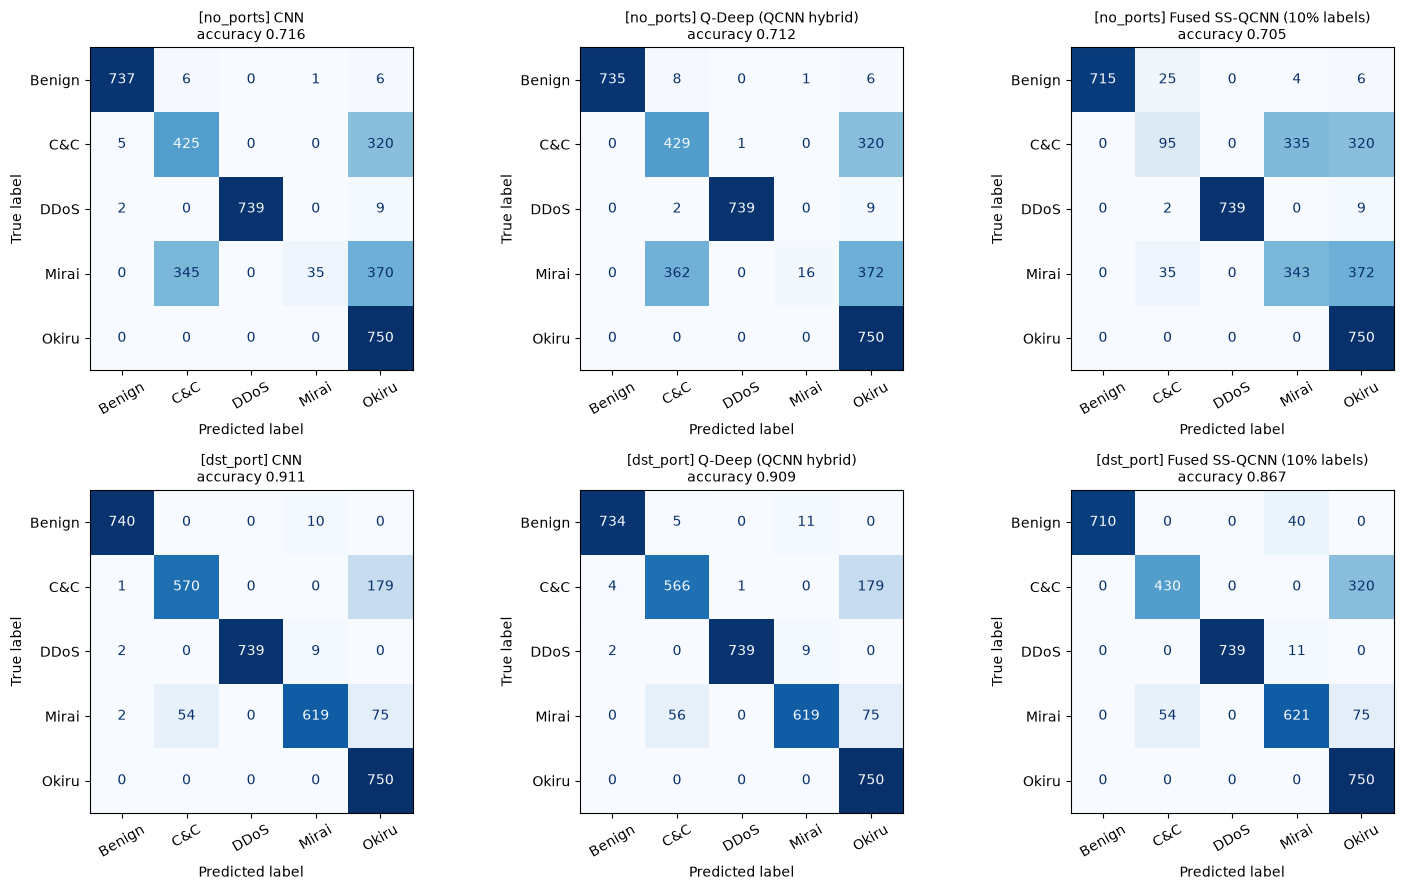

[no_ports] binary view of the fused model: TP=3000 FP=35 FN=0 TN=715 | sensitivity 1.000, specificity 0.953
[dst_port] binary view of the fused model: TP=3000 FP=40 FN=0 TN=710 | sensitivity 1.000, specificity 0.947


In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
show = ["CNN", "Q-Deep (QCNN hybrid)", "Fused SS-QCNN (10% labels)"]
for r, fs in enumerate(FEATURE_SETS):
    y_te_, preds_ = ALL_PREDS[(fs, SEED)]
    for c_, name in enumerate(show):
        ConfusionMatrixDisplay(confusion_matrix(y_te_, preds_[name], labels=range(K)), display_labels=CLASSES).plot(
            ax=axes[r, c_], colorbar=False, cmap="Blues", xticks_rotation=30)
        axes[r, c_].set_title(f"[{fs}] {name}\naccuracy {accuracy_score(y_te_, preds_[name]):.3f}", fontsize=10)
plt.tight_layout(); plt.show()

# binary view (attack = positive class), derived from the five-class predictions of the fused model
for fs in FEATURE_SETS:
    y_te_, preds_ = ALL_PREDS[(fs, SEED)]
    yb, pb = (y_te_ != 0).astype(int), (preds_["Fused SS-QCNN (10% labels)"] != 0).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb, pb).ravel()
    print(f"[{fs}] binary view of the fused model: TP={tp} FP={fp} FN={fn} TN={tn} | sensitivity {tp / (tp + fn):.3f}, specificity {tn / (tn + fp):.3f}")

## 7. Re-drawing the paper's Table 4 / Figures 6-7 next to this notebook

Figure 6 of the paper is a bar chart of Table 4; Figure 7 shows the precision column. The next cell draws the paper's numbers
beside the notebook's means for the six models of Table 4. The mapping of the paper's model names to this notebook's models is: RL -> `RL`,
BPNN -> `BPNN`, MLNN -> `MLNN`, CNN -> `CNN`, Q-Deep Learning model -> `Q-Deep (QCNN hybrid)`, Proposed model -> `Fused SS-QCNN (10% labels)`.

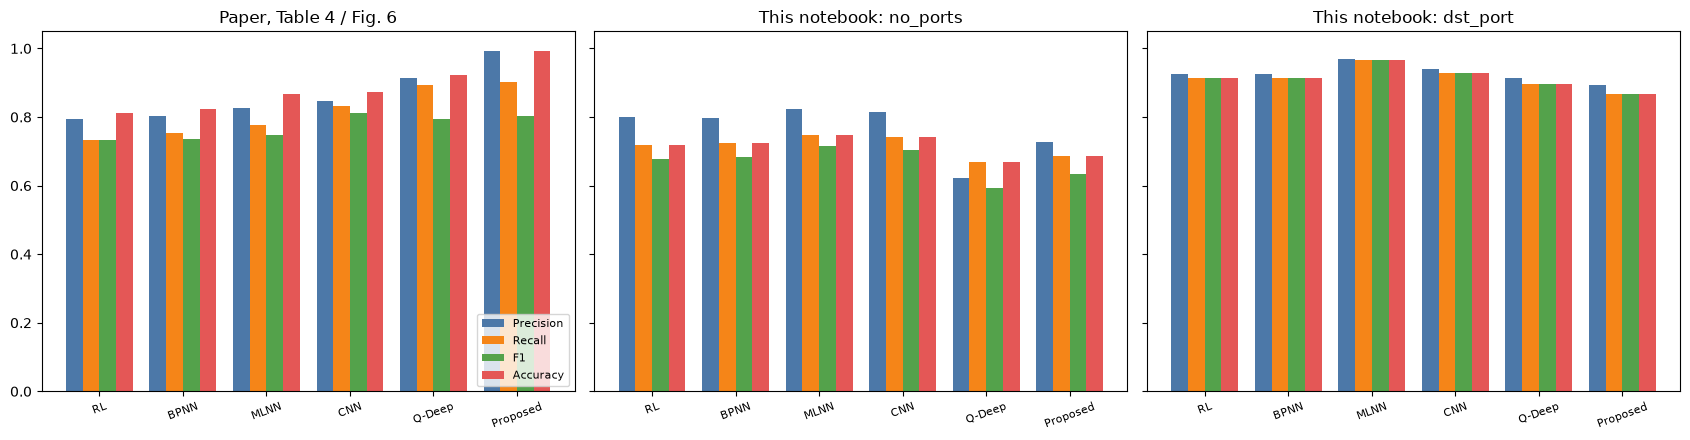

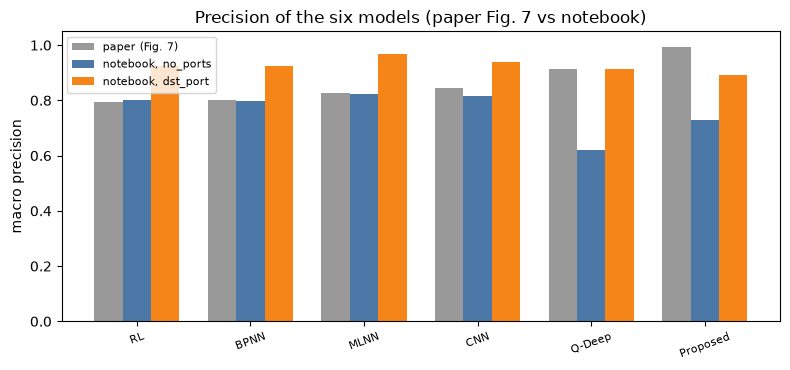

In [17]:
PAPER = {  # Table 4: precision, recall, F1, accuracy
    "RL": (0.7943, 0.73431, 0.73432, 0.81323), "BPNN": (0.80235, 0.75345, 0.73456, 0.82344), "MLNN": (0.8278, 0.7767, 0.7473, 0.86765),
    "CNN": (0.8454, 0.8334, 0.8123, 0.87347), "Q-Deep Learning model": (0.9145, 0.8934, 0.7934, 0.92234),
    "Proposed model": (0.9934, 0.90345, 0.80345, 0.9934)}
MAP = {"RL": "RL", "BPNN": "BPNN", "MLNN": "MLNN", "CNN": "CNN", "Q-Deep Learning model": "Q-Deep (QCNN hybrid)",
       "Proposed model": "Fused SS-QCNN (10% labels)"}
METRICS = ["precision", "recall", "f1", "accuracy"]
MEAN = RES.groupby(["feature_set", "model"])[METRICS].mean()
names = list(PAPER)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, (title, getter) in zip(axes, [("Paper, Table 4 / Fig. 6", lambda n, k: PAPER[n][k]),
                                      ("This notebook: no_ports", lambda n, k: MEAN.loc[("no_ports", MAP[n])][METRICS[k]]),
                                      ("This notebook: dst_port", lambda n, k: MEAN.loc[("dst_port", MAP[n])][METRICS[k]])]):
    xs = np.arange(len(names))
    for k, (mname, col) in enumerate(zip(["Precision", "Recall", "F1", "Accuracy"], ["#4C78A8", "#F58518", "#54A24B", "#E45756"])):
        ax.bar(xs + (k - 1.5) * 0.2, [getter(n, k) for n in names], 0.2, label=mname, color=col)
    ax.set_xticks(xs); ax.set_xticklabels([n.replace(" model", "").replace(" Learning", "") for n in names], rotation=20, fontsize=8)
    ax.set_title(title); ax.set_ylim(0, 1.05)
axes[0].legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8)); xs = np.arange(len(names))
ax.bar(xs - 0.25, [PAPER[n][0] for n in names], 0.25, label="paper (Fig. 7)", color="#999999")
ax.bar(xs, [MEAN.loc[("no_ports", MAP[n])]["precision"] for n in names], 0.25, label="notebook, no_ports", color="#4C78A8")
ax.bar(xs + 0.25, [MEAN.loc[("dst_port", MAP[n])]["precision"] for n in names], 0.25, label="notebook, dst_port", color="#F58518")
ax.set_xticks(xs); ax.set_xticklabels([n.replace(" model", "").replace(" Learning", "") for n in names], rotation=20, fontsize=8)
ax.set_ylabel("macro precision"); ax.set_ylim(0, 1.05); ax.legend(fontsize=8); ax.set_title("Precision of the six models (paper Fig. 7 vs notebook)")
plt.tight_layout(); plt.show()

## 8. Side-by-side comparison with the paper, with a verdict per claim

In [18]:
TOL = 0.02          # "reproduced" = within 0.02 (2 accuracy points / 0.02 F1)
def verdict(paper, got):
    d = got - paper
    return "reproduced" if abs(d) <= TOL else ("exceeded here" if d > 0 else "not reached here")
rows = []
for n in names:
    for k, mname in enumerate(METRICS):
        pv = PAPER[n][k]; rec = dict(model=n, metric=mname, paper=pv)
        for fs in FEATURE_SETS:
            gv = MEAN.loc[(fs, MAP[n])][mname]; rec[fs] = round(gv, 4); rec[f"verdict ({fs})"] = f"{verdict(pv, gv)} ({gv - pv:+.3f})"
        rows.append(rec)
CMP = pd.DataFrame(rows)
print(CMP.to_string(index=False))
print("\nVerdict counts over the 24 cells of Table 4:")
for fs in FEATURE_SETS:
    print(f"  {fs}:", CMP[f"verdict ({fs})"].str.extract(r"^([a-z ]+?) \(")[0].value_counts().to_dict())

                model    metric   paper  no_ports        verdict (no_ports)  dst_port        verdict (dst_port)
                   RL precision 0.79430    0.8007       reproduced (+0.006)    0.9261    exceeded here (+0.132)
                   RL    recall 0.73431    0.7186       reproduced (-0.016)    0.9132    exceeded here (+0.179)
                   RL        f1 0.73432    0.6778 not reached here (-0.056)    0.9136    exceeded here (+0.179)
                   RL  accuracy 0.81323    0.7186 not reached here (-0.095)    0.9132    exceeded here (+0.100)
                 BPNN precision 0.80235    0.7984       reproduced (-0.004)    0.9260    exceeded here (+0.124)
                 BPNN    recall 0.75345    0.7236 not reached here (-0.030)    0.9133    exceeded here (+0.160)
                 BPNN        f1 0.73456    0.6822 not reached here (-0.052)    0.9137    exceeded here (+0.179)
                 BPNN  accuracy 0.82344    0.7236 not reached here (-0.100)    0.9133    exceeded here (

In [19]:
claims = []
order_paper = ["RL", "BPNN", "MLNN", "CNN", "Q-Deep Learning model", "Proposed model"]
for fs in FEATURE_SETS:
    acc = {n: MEAN.loc[(fs, MAP[n])]["accuracy"] for n in order_paper}
    pairs = [(order_paper[i], order_paper[i + 1]) for i in range(len(order_paper) - 1)]
    ok = [acc[b] > acc[a] for a, b in pairs]
    claims.append((fs, "ordering of accuracy RL < BPNN < MLNN < CNN < Q-Deep < Proposed", "reproduced" if all(ok) else f"not reached here ({sum(ok)}/5 adjacent pairs ordered)"))
    claims.append((fs, "Q-Deep (quantum) more accurate than the classical CNN", "reproduced" if acc["Q-Deep Learning model"] > acc["CNN"] else
                   f"not reached here (Q-Deep {acc['Q-Deep Learning model']:.3f} vs CNN {acc['CNN']:.3f})"))
    best = max(acc, key=acc.get)
    claims.append((fs, "proposed model has the highest accuracy of the six", "reproduced" if best == "Proposed model" else f"not reached here (best: {best})"))
    claims.append((fs, "proposed accuracy 0.9934", verdict(0.9934, acc["Proposed model"]) + f" ({acc['Proposed model']:.3f})"))
    auc = RES[RES.feature_set == fs].groupby("model")["auc_ovr"].mean()
    ok_auc = all(auc[MAP[n]] >= 0.70 for n in order_paper)
    claims.append((fs, "AUC >= 0.70 for the compared models (macro one-vs-rest)", "reproduced" if ok_auc else "not reached here"))
    t = RES[RES.feature_set == fs].groupby("model")["seconds"].mean()
    claims.append((fs, "quantum model is faster than classical ones (Section 3.7 text)",
                   f"cannot be checked on a classical simulator (fused {t['Fused SS-QCNN (10% labels)']:.0f} s vs CNN {t['CNN']:.0f} s)"))
claims.append(("both", "F1 column of Table 4 is consistent with its precision and recall (Eq. 12)", "see section 9: not consistent"))
claims.append(("both", "ROC curves, Table 2 device table, Figure 8", "cannot be checked: no data or definition given"))
print(pd.DataFrame(claims, columns=["feature set", "claim", "verdict"]).to_string(index=False))

# Binary view (Benign vs attack, attack = positive), derived from the same five-class predictions: the paper also ran a binary copy of its data.
BIN = RES.groupby(["feature_set", "model"])[["bin_accuracy", "bin_f1"]].mean()
rows = []
for n in names:
    rec = dict(model=n, paper_accuracy=PAPER[n][3])
    for fs in FEATURE_SETS:
        v = BIN.loc[(fs, MAP[n])]["bin_accuracy"]; rec[f"binary acc ({fs})"] = round(v, 4); rec[f"verdict ({fs})"] = f"{verdict(PAPER[n][3], v)} ({v - PAPER[n][3]:+.3f})"
    rows.append(rec)
print("\nBinary view (Benign vs attack): notebook accuracy against the paper's accuracy column (the paper does not say which copy Table 4 is):")
print(pd.DataFrame(rows).to_string(index=False))

feature set                                                                     claim                                                             verdict
   no_ports           ordering of accuracy RL < BPNN < MLNN < CNN < Q-Deep < Proposed                       not reached here (3/5 adjacent pairs ordered)
   no_ports                     Q-Deep (quantum) more accurate than the classical CNN                        not reached here (Q-Deep 0.669 vs CNN 0.741)
   no_ports                        proposed model has the highest accuracy of the six                                       not reached here (best: MLNN)
   no_ports                                                  proposed accuracy 0.9934                                            not reached here (0.685)
   no_ports                   AUC >= 0.70 for the compared models (macro one-vs-rest)                                                          reproduced
   no_ports            quantum model is faster than classical ones (Section 

## 9. Reading the paper critically

In [20]:
print("Internal consistency of the paper's Table 4: F1 recomputed from the paper's own precision and recall (Eq. 12)\n")
rows = []
for n, (p_, r_, f_, a_) in PAPER.items():
    h = 2 * p_ * r_ / (p_ + r_)
    rows.append(dict(model=n, precision=p_, recall=r_, F1_reported=f_, F1_from_P_and_R=round(h, 4), gap=round(f_ - h, 4)))
print(pd.DataFrame(rows).to_string(index=False))
print("\nA macro-averaged F1 can sit below the harmonic mean of macro precision and recall, but not by this much for every row (up to 0.14),")
print("and an accuracy of 0.9934 with a recall of 0.903 would need classes of very different size.")

Internal consistency of the paper's Table 4: F1 recomputed from the paper's own precision and recall (Eq. 12)

                model  precision  recall  F1_reported  F1_from_P_and_R     gap
                   RL    0.79430 0.73431      0.73432           0.7631 -0.0288
                 BPNN    0.80235 0.75345      0.73456           0.7771 -0.0426
                 MLNN    0.82780 0.77670      0.74730           0.8014 -0.0541
                  CNN    0.84540 0.83340      0.81230           0.8394 -0.0271
Q-Deep Learning model    0.91450 0.89340      0.79340           0.9038 -0.1104
       Proposed model    0.99340 0.90345      0.80345           0.9463 -0.1428

A macro-averaged F1 can sit below the harmonic mean of macro precision and recall, but not by this much for every row (up to 0.14),
and an accuracy of 0.9934 with a recall of 0.903 would need classes of very different size.


**What this notebook can and cannot say about the paper.**

1. **The experiment is not reproducible from the text.** The data set is never named ("an existing dataset", "IoT dataset"), the features, the
   sample, the split (70 % + 30 % + "10 % for 10-fold cross-validation"), the architectures, the qubit count, the circuits, the optimiser and the number of
   epochs are all missing. The "proposed fused semi-supervised model" has no equations that tie the reinforcement-learning, the
   semi-supervised CNN and the quantum parts together (Sections 3.1-3.6 are textbook summaries, with several passages that are
   about quantum control of a harmonic oscillator rather than classification). The notebook therefore reproduces the *kind* of experiment, not the paper's numbers.
2. **Table 4 is internally inconsistent** (printed above): the F1 column does not follow from the precision and recall columns,
   the "proposed" accuracy equals its precision to four digits (0.9934), and the numbers carry five significant digits for what is described
   as a controlled experiment on "data gathered from IoMT devices in operation" that is in fact an IoT botnet data set (DDoS, C&C, Mirai, Okiru are IoT-23 / botnet labels, not medical-device data).
   Table 2 (heart-rate monitor, insulin pump, ...) is an illustrative device table and not data.
3. **Medical content.** No IoMT-specific traffic is used. The IoT traffic of IoT-23 (infected consumer IoT devices) stands in for IoMT; nothing in the experiment depends on the medical setting.
4. **The data set decides the difficulty.** On IoT-23 flows, classes defined by *malware family* (Mirai, Okiru) are
   largely classes defined by *capture*. With the destination port every model (even a linear one) separates them, without it two classes (DDoS and Okiru) are
   indistinguishable one-packet flows. A 99 % accuracy therefore says little about quantum advantage; what the dst_port column shows is that the *input* matters far more than the model.
5. **No quantum advantage can be read from this comparison.** On a classical state-vector simulator the quantum models are
   five to ten times slower than the classical networks, and in the full run they are *less* accurate than the classical networks fed with the same eight inputs
   (compare the means and the `std` columns of section 6; seed-to-seed spreads of up to 5-7 accuracy points occur in the `no_ports` setting, where two classes are indistinguishable and
   each model breaks the tie arbitrarily). The fused model's binary (Benign vs attack) accuracy is, however, in the range the paper reports for its proposed model (section 8). The claim that QML "substantially cuts the time" cannot be tested on a simulator.
6. **Semi-supervised learning.** The notebook's fused model uses 10 % of the labels. The row with 100 % labels shows what the label restriction costs (little, at this noise level), and the classical
   semi-supervised CNN row shows what the quantum filters add: a few accuracy points with the destination port (about one standard deviation), nothing in the `no_ports` setting.
7. **Baselines.** A random forest on the same inputs beats every network and every quantum model of the comparison (0.81 vs at most 0.75 without ports, 0.997 vs at most 0.97 with the port);
   the strongest honest reference is the random forest, which the paper does not report.

## 10. Exercises

1. **Capture leakage.** Remove the `Mirai` and `Okiru` classes and merge them into one "botnet scan" class; rerun. How does the accuracy gap between the two feature sets change?
2. **Label budget.** Sweep `LABELLED_FRAC` over 0.01, 0.05, 0.1, 0.3 and 1.0 for the classical semi-supervised CNN and for the fused SS-QCNN. At which budget does the reconstruction cost help?
3. **Circuit depth.** Add a second convolution/pooling stage to `QCNN_GATES` (8 -> 4 -> 2 qubits) and a `<Z>` read-out on qubits 3 and 7. Do the equivalence assertion and the drawing still pass? Does accuracy change?
4. **Noise.** Replace `default.qubit` by `default.mixed` with depolarising noise after every two-qubit gate (p = 0.01) for the QCNN QNode and compare the read-outs with the noiseless ones. (Hint: only the PennyLane circuit, not the PyTorch simulator, supports noise.)
5. **Metrics.** Recompute Table 4 with weighted instead of macro averaging, and with the binary (Benign vs attack) view. Which averaging brings the notebook's F1 closest to the paper's F1 column, and does it ever reproduce the paper's pattern of F1 far below precision and recall?